# 13 · Wannier90 models and surface Green's functions

hopforge reads `seedname_hr.dat` / `seedname_tb.dat` (plus POSCAR / .win / centres), so
DFT-derived Wannier models go straight into every tool. The surface module computes
WannierTools-style surface spectral functions $A(\mathbf k_\parallel,E)=-\frac1\pi\mathrm{Im\,Tr}\,G_s$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hopforge as hf
M = hf.models
%matplotlib inline
from hopforge import io, surface

## 1. Import / export round trip
(Here a hopforge model plays the role of a DFT Wannier model; with your own files just call `read_wannier90`.)

In [2]:
fkm = M.diamond_fkm()
fkm.to_wannier90_hr("fkm_hr.dat")
A = fkm.lat.vectors
pos = np.repeat(fkm.lat.positions, 2, axis=0)
w90 = io.read_wannier90("fkm_hr.dat", lattice=A, positions=pos, spinful=True)
k = np.random.rand(5, 3)
print(w90, " identical H(k):", np.allclose(w90.hamiltonian(k), fkm.hamiltonian(k)))
print("Z2 of the imported model:", hf.z2_3d(w90, 2, nk=30, nscan=31, n_jobs=-1))

<Model 'fkm_hr.dat': dim=3, orbitals=2, spinful=True, bands=4>  identical H(k): True


Z2 of the imported model: (1, 1, 1, 1)


Typical use with real DFT output:
```python
m = hf.io.read_wannier90("Bi2Se3_hr.dat", lattice="POSCAR", positions="Bi2Se3_centres.xyz",
                         spinful=True, spin_order="interleaved")
m.add_onsite(-E_fermi)            # put E_F at zero
```

## 2. TI surface Dirac cone

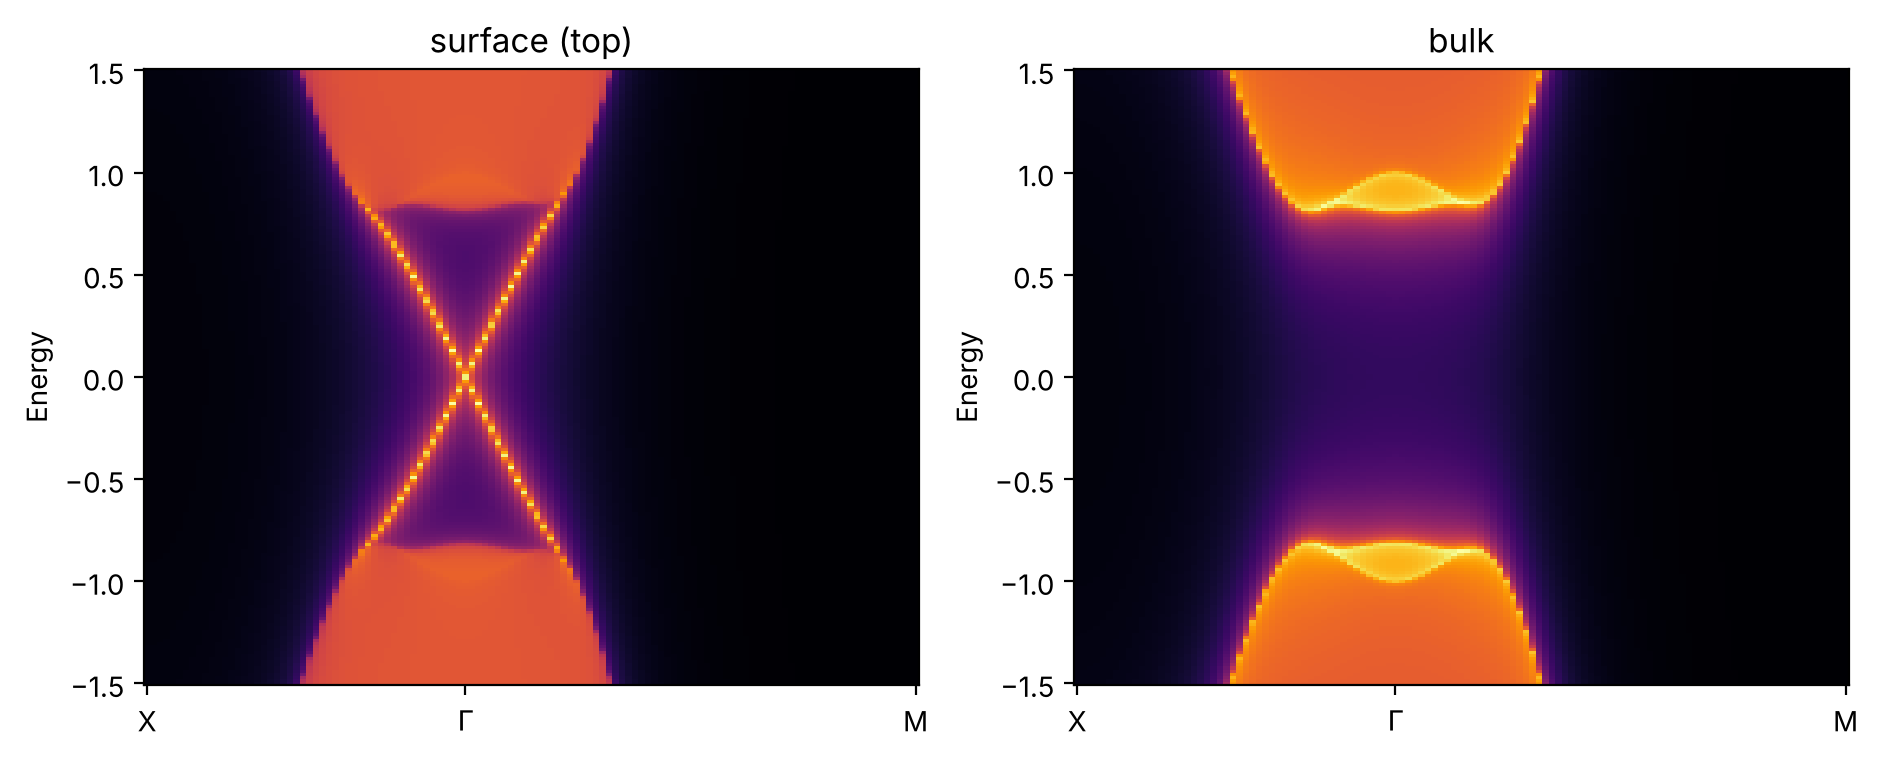

In [3]:
wd = M.wilson_dirac_ti()
path, E, Asurf = surface.spectral(wd, direction=2, kpath=["X", "G", "M"], energies=np.linspace(-1.5, 1.5, 200),
                                  n=120, eta=5e-3, n_jobs=-1)
_, _, Abulk = surface.spectral(wd, 2, ["X", "G", "M"], np.linspace(-1.5, 1.5, 200), n=120, eta=5e-3, bulk=True, n_jobs=-1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
surface.plot_spectral(path, E, Asurf, ax=ax[0], title="surface (top)")
surface.plot_spectral(path, E, Abulk, ax=ax[1], title="bulk");

## 3. Spin-resolved surface spectra: helical edge of the Kane-Mele model
`operator=` gives $-\frac1\pi\mathrm{Im\,Tr}[O\,G_s]$. On the top edge, right movers carry spin up and left movers spin down.

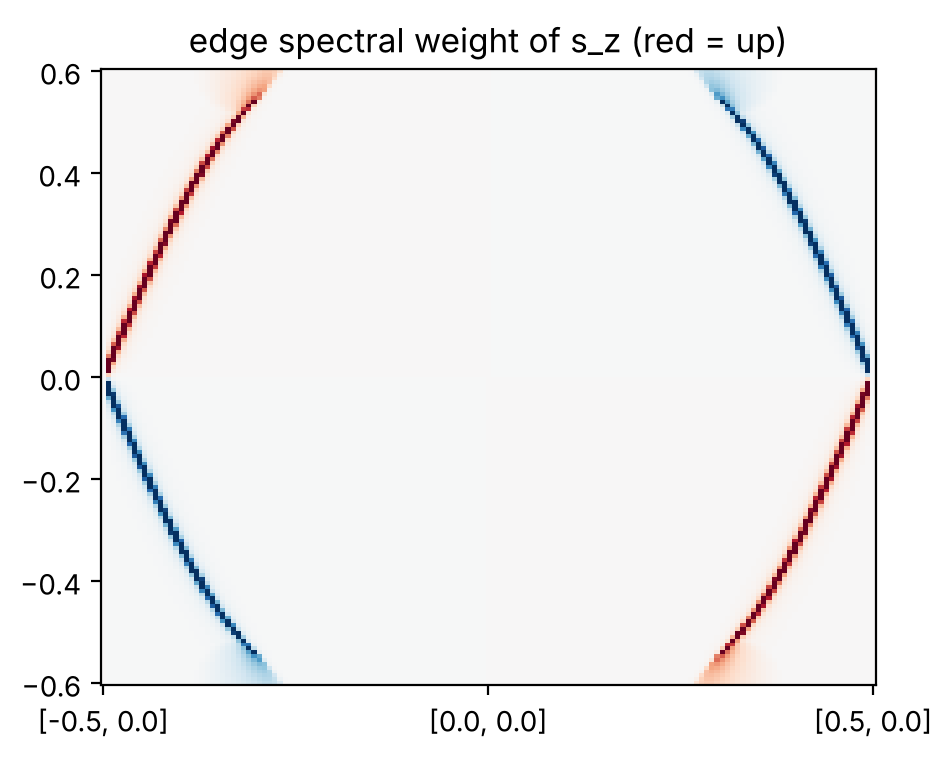

In [4]:
km = M.kane_mele(lso=0.1)
Sz = km.spin_operator('z')
path, E, Asz = surface.spectral(km, direction=1, kpath=[[-0.5, 0], [0, 0], [0.5, 0]],
                                energies=np.linspace(-0.6, 0.6, 160), n=150, eta=3e-3, operator=Sz, n_jobs=-1)
fig, ax = plt.subplots(figsize=(5, 4))
v = np.abs(Asz).max() / 20
ax.pcolormesh(path.x, E, Asz.T, cmap="RdBu_r", vmin=-v, vmax=v, shading="auto")
ax.set_xticks(path.ticks); ax.set_xticklabels(path.labels); ax.set_title("edge spectral weight of s_z (red = up)");

Note: in the idealised 4-band Wilson-Dirac TI the z-surface states are eigenstates of $\tau_y\sigma_z$, so the bare in-plane spin $\langle\tau_0\sigma_{x,y}\rangle$ vanishes on that surface and the locked texture is carried by orbital-spin operators. Realistic Wannier models of Bi$_2$Se$_3$ do give a finite spin polarisation.

## 4. Weyl semimetal Fermi arcs

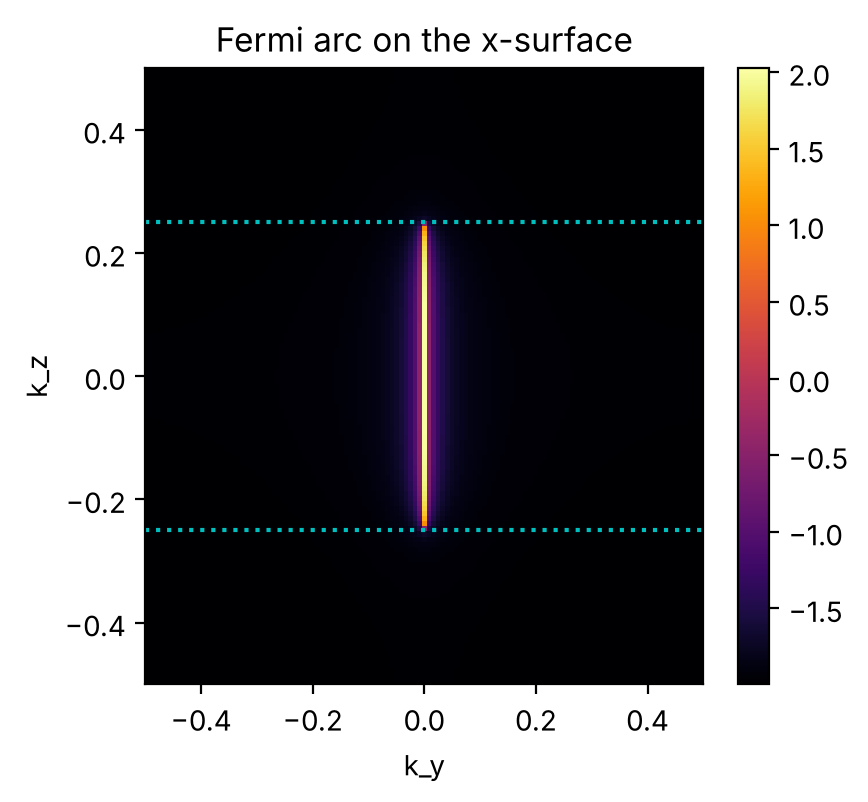

In [5]:
w = M.weyl_minimal()
K1, K2, Aarc = surface.fermi_arc_map(w, direction=0, energy=0.0, nk=121, eta=3e-3, n_jobs=-1)
hf.plot_kmap(np.log10(Aarc + 1e-2), extent=(-0.5, 0.5, -0.5, 0.5), symmetric=False, cmap="inferno",
             title="Fermi arc on the x-surface")
plt.xlabel("k_y"); plt.ylabel("k_z"); plt.axhline(0.25, c="c", ls=":"); plt.axhline(-0.25, c="c", ls=":");

## 5. Kane-Mele edge spectral function (2D model, 1D edge)

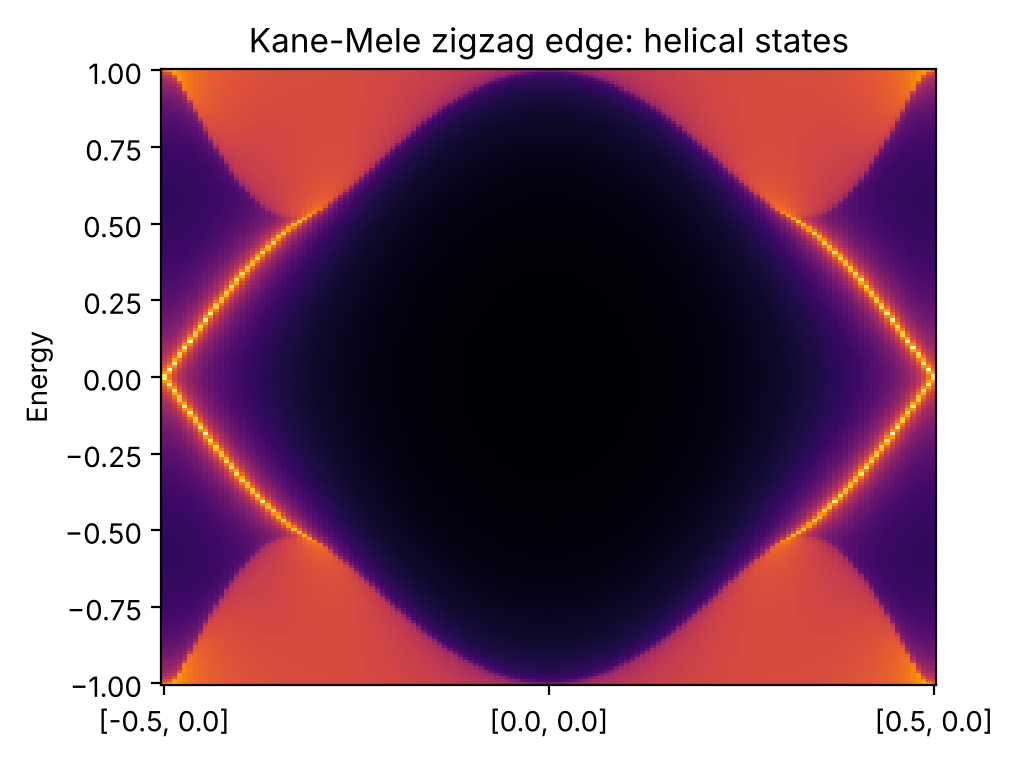

In [6]:
km = M.kane_mele(lso=0.1)
path, E, Aedge = surface.spectral(km, direction=1, kpath=[[-0.5, 0], [0, 0], [0.5, 0]],
                                  energies=np.linspace(-1, 1, 200), n=150, eta=3e-3, n_jobs=-1)
surface.plot_spectral(path, E, Aedge, title="Kane-Mele zigzag edge: helical states");

## Exercises
1. Compare the surface spectral function with slab bands (`wd.slab(2, 20)`).
2. Plot the bottom surface (`side="bottom"`) and explain the difference.
3. Import your own Wannier90 model and plot its surface states.

---
## Quiz 13: Wannier90 and surface states

Twenty multiple-choice questions on this module. Run the next cell for a clickable
version (needs `ipywidgets`), or use the text version below it and grade yourself with
`quiz.check({1: 'a', 2: 'c', ...})`.

In [7]:
quiz = hf.Quiz(13)
quiz.interactive()

In [8]:
quiz.show()

=== Quiz 13: Wannier90 models and surface Green's functions ===

Q1. In Wannier90's hr.dat, the matrix element stored is
   (a) the position operator
   (b) H_mn(R) = <m, 0|H|n, R> times the Wigner-Seitz degeneracy weight
   (c) the overlap
   (d) the band energy

Q2. Why do Wannier centres (positions) matter when importing a model?
   (a) they enter the atomic-gauge phases: Berry phases, polarisation, real-space geometry
   (b) they don't
   (c) they change band energies
   (d) they set the Fermi level

Q3. seedname_tb.dat contains, beyond hr.dat,
   (a) the k-path
   (b) the DOS
   (c) the lattice vectors and the position matrix r_mn(R)
   (d) the charge density

Q4. For spinor Wannier functions, 'interleaved' order means
   (a) spin is dropped
   (b) (orb1 up, orb1 dn, orb2 up, ...)
   (c) random order
   (d) (all up, then all down)

Q5. Reading a monolayer with dim=2
   (a) doubles the cell
   (b) makes it 1D
   (c) removes spin
   (d) drops hoppings with R_z != 0 (vacuum direction

In [9]:
my_answers = {
    1: '',
    2: '',
    3: '',
    4: '',
    5: '',
    6: '',
    7: '',
    8: '',
    9: '',
    10: '',
    11: '',
    12: '',
    13: '',
    14: '',
    15: '',
    16: '',
    17: '',
    18: '',
    19: '',
    20: '',
}
quiz.check(my_answers)

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)
Q6: (no answer)
Q7: (no answer)
Q8: (no answer)
Q9: (no answer)
Q10: (no answer)
Q11: (no answer)
Q12: (no answer)
Q13: (no answer)
Q14: (no answer)
Q15: (no answer)
Q16: (no answer)
Q17: (no answer)
Q18: (no answer)
Q19: (no answer)
Q20: (no answer)

Score: 0 / 20


0